In [230]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
import scanpy as sc
import re
from tqdm.auto import tqdm
from anndata import AnnData
import pandas as pd
import plotly.express as px

In [247]:
def _check_robustness_fractions(
    df_pivot, 
    threshold_qval=0.1, # adjusted p value
    threshold_valid=0.5, # fraction of results required to even consider this condition. I.e. if the test only ran for one set of thresholds, then it is not very robust.
    threshold_below_alpha=0.75, # fraction of results that need to be significant
):
    n_total = np.prod(df_pivot.shape)
    n_valid = n_total - df_pivot.isna().sum().sum()
    n_below_alpha = (df_pivot < threshold_qval).sum().sum() # number of results below pval threshold, i.e., number of significant results
    frac_valid_results = (n_valid / n_total)
    frac_pval_below_alpha = (n_below_alpha / n_valid) # fraction of significant results relative to valid results
    is_robust = (frac_pval_below_alpha > threshold_below_alpha) & (frac_valid_results > threshold_valid)
    return frac_valid_results, frac_pval_below_alpha, is_robust


def check_robustness(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_VALID = 0.5,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)

    df2 = df.copy()
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                df_pivot_nes = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="NES")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                    df_combined2 = pd.concat([df2, df_pivot_nes])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged2 = df_combined2.combine_first(df_pivot_nes)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_merged2 = df_merged2.loc[~df_merged2.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                df_pivot_nes = df_merged2.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(
                    df_pivot,
                    threshold_qval=THRESHOLD_QVAL,
                    threshold_valid=THRESHOLD_VALID,
                    threshold_below_alpha=THRESHOLD_BELOW_ALPHA
                )
                
                if is_robust:
                    # print(df_pivot_nes.max().max(), df_pivot_nes.min().min())
                    if (df_pivot_nes.max().max() > 0) and (df_pivot_nes.min().min() < 0):
                        sns.heatmap(df_pivot, cmap="Reds_r", center=0, vmin=0, vmax=0.1, square=True)
                        plt.show()
                        sns.heatmap(df_pivot_nes, cmap="RdBu_r", center=0, square=True)
                        plt.show()
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results


def get_robust_significant_results(
    results,
    alphas,
    threshold_valid,
    threshold_below_alpha,
):

    results_robust = []
    for alpha in alphas:
        results_robust.append(check_robustness(results, THRESHOLD_QVAL=alpha, THRESHOLD_VALID=threshold_valid, THRESHOLD_BELOW_ALPHA=threshold_below_alpha))
    results_robust = pd.concat(results_robust)
    results_robust = results_robust.groupby(["contrast", "celltype_combo", "cytokine"])["qval_threshold"].min().to_frame().reset_index()
    
    # results_mean = results.fillna(0).groupby(["contrast", "celltype_combo", "cytokine"])["NES"].mean().to_frame().reset_index()
    results_mean = results.groupby(["contrast", "celltype_combo", "cytokine"])["NES"].mean().to_frame().reset_index()
    results_pivot = results_mean.pivot(
        index="cytokine",
        columns="celltype_combo",
        values="NES",
    )
    df_annot = results_pivot.copy()
    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)
        df_annot[:] = ""
    for cytokine in df_annot.index:
        for celltype in df_annot.columns:
            qval = results_robust.loc[(results_robust.cytokine == cytokine) & (results_robust.celltype_combo == celltype)].qval_threshold
            if len(qval) != 0:
                qval = qval.values[0]
                if qval == 0.1:
                    df_annot.loc[cytokine, celltype] = "*"
                if qval == 0.05:
                    df_annot.loc[cytokine, celltype] = "**"
                if qval == 0.01:
                    df_annot.loc[cytokine, celltype] = "***"

    return results_pivot, df_annot, results_robust


def replace_greek(x):
    x = x.replace("alpha", "α")
    x = x.replace("beta", "β")
    x = x.replace("gamma", "γ")
    x = x.replace("lambda", "λ")
    x = x.replace("epsilon", "ε")    
    x = x.replace("omega", "ω")
    return x



def get_receivers(
    adata: AnnData, 
    cytokine_info: pd.DataFrame,
    cytokine: str | list[str],
    column_cell_type: str = "labels"
) -> pd.DataFrame | None:

    if isinstance(cytokine, (list, np.ndarray, pd.Index)):
        results = [get_receivers(adata, cytokine_info, c, column_cell_type) for c in cytokine]
        return pd.concat(results, axis=0)

    assert isinstance(cytokine, str), type(cytokine)
    
    # get receptor genes for this cytokine
    _receptor_genes = cytokine_info.loc[cytokine_info.name == cytokine, "receptor gene"]
    if _receptor_genes.isna().all():
        print(f"No receptor gene found in cytokine_info for cytokine: {cytokine}")
        return None
    assert len(_receptor_genes) == 1, _receptor_genes
    _receptor_genes = _receptor_genes.values[0]

    # there can be multiple receptors
    candidates = re.split("; ", _receptor_genes)
    
    results_mean, results_frac = [], []
    # each receptor may require the expression of multiple genes
    for candidate in candidates:
        genes = np.array(re.split(", ", candidate))
        mask = np.isin(genes, adata.var_names)
        if not mask.any():
            print(f"None of the cytokine receptor genes ({genes}) were found in dataset for cytokine {cytokine}.")
            continue
        if not mask.all():
            print(f"The following cytokine receptor genes were not found in the dataset and are excluded: {genes[~mask]}")
            genes = genes[mask]
        X_df = adata[:, genes].to_df()
        frac_df = X_df > 0
        X_df.loc[:, column_cell_type] = adata.obs.loc[:, column_cell_type].values
        frac_df.loc[:, column_cell_type] = adata.obs.loc[:, column_cell_type].values
        # take minimum average gene expression across all genes required for this receptor
        results_mean.append(X_df.groupby(column_cell_type, observed=False).mean().min(axis=1).to_frame())
        # take minimum expression fraction across all genes required for this receptor
        results_frac.append(frac_df.groupby(column_cell_type, observed=False).mean().min(axis=1).to_frame())
    if len(results_mean) == 0:
        return None

    
    results_mean = pd.concat(results_mean, axis=1).max(axis=1).to_frame().rename({0: "mean_X"}, axis=1)
    results_frac = pd.concat(results_frac, axis=1).max(axis=1).to_frame().rename({0: "frac_X"}, axis=1)
    results = pd.concat([results_mean, results_frac], axis=1)
    results.loc[:, "cytokine"] = cytokine
    return results


def get_program_associated_cytokines(df, program, cell_type):
    return df.loc[df.process_id.str.contains(program) & (df.cell_type == cell_type), ["cyt", "direction"]]


def get_plotting_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict,
    cell_type_data,
    program,
    cell_type_data_column,
    cytokine_column,
    alpha,
) -> pd.DataFrame:
    
    # get program-associated cytokines
    cytokines = get_program_associated_cytokines(significant_effects_df, program, cell_type_dict)
    unique_cytokines = cytokines.cyt.unique()
    directions = cytokines.direction.values
    
    # get relevant enrichment results
    _results = results.loc[
        (results.loc[:, cell_type_data_column] == cell_type_data) 
        & (results.loc[:, cytokine_column].isin(unique_cytokines))
    ]
    
    # get enrichment scores
    valid_cytokines = np.intersect1d(unique_cytokines, _results.cytokine.unique())
    missing_cytokines = cytokines.cyt[~np.isin(unique_cytokines, valid_cytokines)]
    nes = _results.set_index("cytokine").loc[valid_cytokines].groupby("cytokine")["NES"].mean().sort_values(ascending=False).to_frame()
    
    missing_nes = pd.DataFrame(np.zeros(len(missing_cytokines)), index=missing_cytokines, columns=["NES"])
    nes = pd.concat([nes, missing_nes], axis=0)
    
    nes.loc[nes.NES > 0, "color_enrichment"] = "#FF007F"
    nes.loc[nes.NES < 0, "color_enrichment"] = "#4575B4"
    nes.loc[:, "direction"] = cytokines.set_index("cyt").loc[nes.index]
    nes.loc[nes.direction > 0, "color_direction"] = "red"#"#FF007F"
    nes.loc[nes.direction <= 0, "color_direction"] = "blue"#"#4575B4"
    significant_cytokines = results_robust.loc[
        (
            (results_robust.celltype_combo == cell_type_data)
            & (results_robust.qval_threshold <= alpha)
        )
    ]

    significant_cytokines = significant_cytokines.cytokine.unique()
    significant_cytokines = significant_cytokines[np.isin(significant_cytokines, nes.index)]
    nes.loc[:, "significant"] = False
    nes.loc[significant_cytokines, "significant"] = True
    nes.loc[:, "opacity_significance"] = nes.significant.apply(lambda x: 0.8 if x else 0.5)
    nes = nes.sort_values(["NES", "direction"], ascending=[False, True])
    return nes, cytokines


def plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict,
    cell_type_data,
    program,
    cell_type_data_column: str = "celltype_combo",
    cytokine_column: str = "cytokine",
    path: str | None = None,
    alpha: float = 0.1,
    width = 300,
    height = 300,
    title: str | None = None,
    debug_display_nes: bool = False,
    adata: AnnData | None = None,
    cytokine_info: pd.DataFrame | None = None,
    receptor_expression_threshold: float = 1e-5,
):
    
    nes, cytokines = get_plotting_data(
        results,
        results_robust,
        significant_effects_df,
        cell_type_dict,
        cell_type_data,
        program,
        cell_type_data_column,
        cytokine_column,
        alpha,
    )
    
    if debug_display_nes:
        display(nes)
    
    # create figure
    thetas = (np.arange(len(cytokines)) / len(cytokines)) * 360
    if len(thetas) > 1:
        dtick = thetas[1] - thetas[0]
    else:
        dtick = 0

    max_radius = 1.1*nes["NES"].max()

    fig = go.Figure(
        go.Barpolar(
            r=nes["NES"].abs().values,
            theta=thetas,
            width=np.ones_like(thetas) * 0.6 * (360 / len(cytokines)),

            marker=dict(
                color=nes.color_enrichment,
                line_color=nes.color_enrichment,
                line_width=0.5,
                opacity=nes.opacity_significance
            ),
            
        )
    )
    
    ticklabels = []
    for row_i, row in nes.iterrows():
        cytokine = row.name
        label = cytokine
        # if row.significant:
        #     label = f"<b>{cytokine}*</b>"
        
        #if row.direction == 1:
        #    label = f'<span style="color:red;">{label}</b></span>'
        #else:
        #    label = f'<span style="color:blue;">{label}</b></span>'

        if row.significant:
            label = f"{label}*"
            
        ticklabels.append(label)
        
    fig.update_layout(
        width=width,
        height=height,
        margin=dict(
            l=20,  # Left margin
            r=20,  # Right margin
            t=20,  # Top margin
            b=20   # Bottom margin
        ),
        template=None,
        showlegend=False,
        polar = dict(
            bgcolor='#f0f0f0',
            # bgcolor='white',
            radialaxis = dict(
                linewidth=0.5,
                showline=True,
                range=[0, max_radius],
                showticklabels=True,
                showgrid=True,
                # tickvals=np.arange(0, np.ceil(max_radius), dtype=int),
                tickvals=[0, 1],
                gridcolor='lightgray',
                tickfont=dict(
                    color='black',
                ),
                layer='below traces',
                ticklen=0,
            ),
            angularaxis = dict(
                showticklabels=False,
                ticks="outside",
                dtick=dtick,
                tickvals=thetas,
                ticktext=ticklabels,
                tickangle=0,
                rotation=90,
                layer='below traces',
                ticklen=0,
            ),
        ),
        font=dict(
            family="Arial",
            size=6,
            color="black"
        ),
    )

    if adata is not None:
        assert isinstance(cytokine_info, pd.DataFrame)

        def receptor_expression_to_color(x):
            if np.isnan(x):
                return "lightgray"
            if x > receptor_expression_threshold:
                return "black"
            return "white"
        
        df_receptor_expression_stats = get_receivers(
            adata,
            cytokine_info,
            cytokine = nes.index,
            column_cell_type = "labels",
        ).set_index("cytokine")
        
        nes = pd.concat([nes, df_receptor_expression_stats], axis=1)            
        nes.loc[:, "color_receptor"] = nes.mean_X.apply(receptor_expression_to_color)
        textures = ""#nes.mean_X.apply(lambda x: "x" if np.isnan(x) else "").values
        fig.add_trace(
            go.Barpolar(
                base=[1.01*nes["NES"].max()] * len(nes), 
                r=[1.1*max_radius] * len(nes),
                theta=thetas,
                width=0.9*dtick,
                marker=dict(
                    color=nes.color_receptor,
                    line_color="black",#nes.direction,
                    line_width=2,
                    pattern=dict(
                        shape=textures,
                        size=4,
                        bgcolor="white",
                        fgcolor=nes.color_receptor
                    ),
                    opacity=1,
                ),
            )
        )
    
    center_x, center_y = 0.5, 0.5
    label_radius = 0.5
    
    annotations = []
    for theta_deg, text_html in zip(thetas, ticklabels):
        th = np.deg2rad(theta_deg-90)
        x = center_x - label_radius * np.cos(th)
        y = center_y - label_radius * np.sin(th)
    
        text_angle = 90 - theta_deg
        ang_norm = ((text_angle + 180) % 360) - 180
        
        if ang_norm > 90:
            text_angle -= 180
        if ang_norm < -90:
            text_angle += 180
        
        if x < center_x - 1e-6:
            xanchor = "right"
        elif x > center_x + 1e-6:
            xanchor = "left"
        else:
            xanchor = "center"
    
        if y < center_y - 1e-6:
            yanchor = "top"
        elif y > center_y + 1e-6:
            yanchor = "bottom"
        else:
            yanchor = "middle"
    
        annotations.append(
            dict(
                x=x, y=y,
                xref="paper", yref="paper",
                text=text_html,
                showarrow=False,
                textangle=text_angle,
                xanchor=xanchor, yanchor=yanchor,
                font=dict(size=6, family="Arial"),
                align="center",
                bgcolor="rgba(0,0,0,0)"
            )
        )
    fig.update_layout(annotations=annotations)

    
    if title is not None:
        fig.update_layout(
            title=dict(
                text=title,
                font=dict(size=6, color='black', family="Arial"),
                x=0.5,
                y=1,
            ),
        )
    if path:
        fig.write_image(path)
    fig.show()


def make_bar_chart(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict,
    cell_type_data,
    program,
    cell_type_data_column,
    cytokine_column,
    adata,
    cytokine_info,
    alpha: str = 0.1,
    path: str | None = None,
    width = 100,
    height = 100,
    title = None,
) -> pd.DataFrame:

    nes, cytokines = get_plotting_data(
        results=results,
        results_robust=results_robust,
        significant_effects_df=significant_effects_df,
        cell_type_dict = cell_type_dict,
        cell_type_data = cell_type_data,
        program = program,
        cell_type_data_column = cell_type_data_column,
        cytokine_column = cytokine_column,
        alpha = alpha,
    )

    assert isinstance(cytokine_info, pd.DataFrame)
    
    def receptor_expression_to_color(x, receptor_expression_threshold=0):
        if np.isnan(x):
            return "lightgray"
        if x > receptor_expression_threshold:
            return "black"
        return "white"
    
    def receptor_expression_to_pattern(x, receptor_expression_threshold=0):
        if x > receptor_expression_threshold:
            return ""
        return "//"
    
    df_receptor_expression_stats = get_receivers(
        adata,
        cytokine_info,
        cytokine = nes.index,
        column_cell_type = "labels",
    ).set_index("cytokine")
    display(df_receptor_expression_stats)
    nes = pd.concat([nes, df_receptor_expression_stats], axis=1)            
    nes.loc[:, "color_receptor"] = nes.mean_X.apply(receptor_expression_to_color)
    nes.loc[:, "receptor_pattern"] = nes.mean_X.apply(receptor_expression_to_pattern)
    
    df = nes.reset_index().rename({"index": "cytokine"}, axis=1)
    df.loc[:, "NES"] = df.loc[:, "NES"].fillna(0)
    df = df.sort_values(["direction", "NES"])
    
    palette = df.groupby("direction")["color_direction"].unique().to_frame().reset_index()
    # palette.loc[:, "color_direction"] = palette.loc[:, "color_direction"].apply(lambda x: x[0])
    palette.loc[:, "color_direction"] = palette.loc[:, "color_direction"].apply(lambda x: "blue" if x == -1 else "red")
    palette = dict(zip(palette.direction, palette.color_direction))

    custom_palette = {
        "1": 'rgb(230, 0, 126)', # Pink/Magenta for positive effect (Up/Increase)
        "-1": 'rgb(70, 100, 140)' # Dark Blue/Slate for negative effect (Down/Decrease)
    }
    
    fig_bar = px.bar(
        df,
        x='cytokine',
        y='NES',
        color='direction',                             
        color_discrete_map=custom_palette,#palette,          
        category_orders={"direction": [1.0, -1.0]},
        labels={'NES': 'NES', "cytokine": ""},    
        height=height,
        width=width,
        pattern_shape=nes.receptor_pattern,
    )

    fig_bar.update_layout(
        font_family="Arial",
        title_font_size=6,
        title_x=0.5,
        title=title,
        plot_bgcolor='rgba(0,0,0,0)',
        paper_bgcolor='rgba(255,255,255,1)',
        showlegend=False,
        font=dict(family="Arial", size=6),
        yaxis=dict(
            range=[min(-0.05, df['NES'].min() - 0.1), max(0.05, df['NES'].max() + 0.1)],
            showgrid=True,
            gridcolor='lightgray',
            zeroline=True,
            zerolinewidth=2.5, # THICKER LINE
            zerolinecolor='black',
            tickfont=dict(size=6, family="Arial")
        ),
        xaxis=dict(
            showgrid=False,
            gridcolor='lightgray',
            tickfont=dict(size=6, family="Arial"),
            tickangle=90,
            categoryorder='array',
            categoryarray=df.cytokine
        ),
        margin=dict(l=0, r=0, t=20, b=0, pad=0),
    )
    fig_bar.update_coloraxes(showscale=False)
    fig_bar.update_traces(marker_line_width=1)
    fig_bar.update_traces(marker_line_width=0, marker=dict(pattern=dict(size=5, solidity=0.3,)))
    if path:
        # fig_bar.write_image(f"./results_final_DEGs/figures/bar_plot_{program}_{cell_type_data}_{tissue}.svg")
        fig_bar.write_image(path)
    fig_bar.show()
    return nes

In [445]:
def _get_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict,
    cell_type_data,
    program,
    cell_type_data_column,
    cytokine_column,
    adata,
    cytokine_info,
    receptor_expression_threshold=0.01,
    receptor_fraction_threshold=0.05,
    alpha=0.05,
):
    nes, cytokines = get_plotting_data(
        results=results,
        results_robust=results_robust,
        significant_effects_df=significant_effects_df,
        cell_type_dict = cell_type_dict,
        cell_type_data = cell_type_data,
        program = program,
        cell_type_data_column = cell_type_data_column,
        cytokine_column = cytokine_column,
        alpha = alpha,
    )

    assert isinstance(cytokine_info, pd.DataFrame)
    
    def receptor_expression_to_color(x, receptor_expression_threshold=receptor_expression_threshold):
        if np.isnan(x):
            return "lightgray"
        if x > receptor_expression_threshold:
            return "black"
        return "white"
    
    def receptor_expression_to_pattern(x, receptor_expression_threshold=receptor_expression_threshold):
        if x > receptor_expression_threshold:
            return ""
        return "//"
    
    df_receptor_expression_stats = get_receivers(
        adata,
        cytokine_info,
        cytokine = nes.index,
        column_cell_type = "labels",
    ).set_index("cytokine")
    nes = pd.concat([nes, df_receptor_expression_stats], axis=1)            
    nes.loc[:, "color_receptor"] = nes.mean_X.apply(receptor_expression_to_color)
    nes.loc[:, "receptor_pattern"] = nes.mean_X.apply(receptor_expression_to_pattern)
    
    df = nes.reset_index().rename({"index": "cytokine"}, axis=1)
    df.loc[:, "NES"] = df.loc[:, "NES"].fillna(0)
    df = df.sort_values(["NES"], ascending=False).reset_index()
    return df


def make_plot(df_nes, path, direction_palette, receptor_palette):
    fig, axs = plt.subplots(2,1,figsize=(0.2 * df_nes.shape[0], 0.7), sharex=True, height_ratios=(0.92, 0.08))
    ax = axs[0]
    display(df_nes)
    sns.barplot(
        data=df_nes,
        x="cytokine",
        y="NES",
        hue="direction",
        palette=direction_palette,
        legend=False,
        ax=ax,
        order=df_nes.cytokine,
    )

    heights = [p.get_height() for p in ax.patches]
    patch_order = np.argsort(heights)[::-1]
    
    for patch_i, (_, row) in zip(patch_order, df_nes.iterrows()):
        patch = ax.patches[patch_i]
        x, y = patch.get_xy()
        width, height = patch.get_width(), patch.get_height()
        if row["significant"] == True:
            ax.text(x+0.25*width, y+0.6*height, "*", fontsize=10, family="Arial", color="white")
    
    ax.set_title(f"{program} in {cell_type_dataset}", fontsize=6, family="Arial", pad=-1)
    ax.set_xlabel("")
    ax.set_ylabel("NES", fontsize=6, family="Arial")
    ax.tick_params(axis="x", length=0)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xticks([])
    yticks = ax.get_yticks()
    yticks = np.arange(yticks[0], yticks[-1], 1, dtype=int)
    ytickslabels = [str(l) for l in yticks]
    ax.set_yticks(yticks, ytickslabels, fontsize=6, family="Arial")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.margins(y=0.05)
    
    
    axr = axs[1]
    axr.spines[['top', 'right', "left", "bottom"]].set_visible(False)
    sns.barplot(
        data=df_nes.loc[df_nes.color_receptor == "black"],
        x="cytokine",
        y=0.15,
        hue="color_receptor",
        palette=receptor_palette,
        legend=False,
        ax=axr,
        edgecolor="k",
        linestyle="-",
        linewidth=0.5,
        order = df_nes.cytokine
    )
    sns.barplot(
        data=df_nes.loc[df_nes.color_receptor != "black"],
        x="cytokine",
        y=0.15,
        hue="color_receptor",
        palette=receptor_palette,
        legend=False,
        ax=axr,
        edgecolor="k",
        linestyle="--",
        linewidth=0.5,
        order = df_nes.cytokine
    )
    axr.set_xlabel("")
    axr.set_ylabel("")
    axr.set_yticks([])
    axr.set_xticks(np.arange(df_nes.shape[0]), df_nes.cytokine, fontsize=6, family="Arial", rotation=90)
    axr.tick_params(axis="x", length=1)
    axr.set_xlim([-0.5, df_nes.shape[0]-0.5])
    
    if path:
        plt.savefig(f"./final_figures/barplot_{program}_{cell_type_dataset}.svg", bbox_inches="tight", pad_inches=0, transparent=True)
    plt.show()

In [3]:
THRESHOLD_VALID = 1/3
THRESHOLD_BELOW_ALPHA = 2/3
THRESHOLD_EXPRESSION = 0.05
THRESHOLD_DUPLICATES = 0.01

In [4]:
adata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/08_Multiple_Sclerose/Schafflick20_MS_CSF.h5ad")
invalid_labels = [
    "Mono Doublet",
    "contamination1",
    "B cell doublets",
    "doublet",
]
adata = adata[~adata.obs.labels.isin(invalid_labels)]
adata.obs.loc[:, "tissue"] = adata.obs.loc[:, "CSF"].apply(lambda x: "csf" if x == "True" else "blood")

/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


In [5]:
cytokine_info = "/Users/soeren.becker/repos/HumanCytokineDict/annotations/20250125_cytokine_info_with_functional_classification_LV.xlsx"
cytokine_info = pd.read_excel(cytokine_info)
cytokine_info.loc[cytokine_info.name.isin(["IL-2", "IL-21", "IL-7"])]
cytokine_info.loc[:, "name"] = cytokine_info.loc[:, "name"].apply(replace_greek)


In [6]:
tissue = "blood"
results = pd.read_csv(f"./results_final_DEGs/results_MS_{tissue}_robustness_new.csv")
results.loc[:, "cytokine"] = results.cytokine.apply(replace_greek)
results = results.loc[results.threshold_expression >= THRESHOLD_EXPRESSION]
results = results.loc[results.percent_duplicate_ranking_stats < THRESHOLD_DUPLICATES]
results_pivot, df_annot, results_robust = get_robust_significant_results(
    results,
    alphas=[0.1, 0.05, 0.01],
    threshold_valid=THRESHOLD_VALID,
    threshold_below_alpha=THRESHOLD_BELOW_ALPHA,
)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

In [7]:
all_effects_df = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/all_effects.csv", index_col=0)
significant_effects_df = all_effects_df[all_effects_df['is_significant'] == 1]

In [410]:
direction_palette = {1: "#1B9E77", -1: "#7570B3",}
receptor_palette = {"black": "k", "lightgray": "darkgray", "white": "white"}

The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']


,index,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,0,IL-2,1.695324,#FF007F,-1.0,blue,True,0.8,1.035242,0.603704,black,
1,1,IL-15,1.681274,#FF007F,-1.0,blue,True,0.8,1.035242,0.603704,black,
2,2,IL-12,1.274155,#FF007F,-1.0,blue,False,0.5,0.222341,0.162963,black,
3,3,IL-10,1.221602,#FF007F,1.0,red,False,0.5,0.169883,0.133333,black,


/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.



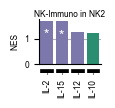

In [446]:
cell_type_data = 'NK2 (NK_CD56hi)'
cell_type_dict = "NK CD56hi"
program = "NK-Immuno"

cell_type_dataset = cell_type_data.split(" (")[0]
df_nes = _get_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    adata = adata[(adata.obs.labels==cell_type_dataset) & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
    receptor_expression_threshold=0.05,
)

make_plot(df_nes, f"./final_figures/barplot_{program}_{cell_type_dataset}.svg", direction_palette, receptor_palette)

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']
None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-α.


,index,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,0,IL-21,1.559819,#FF007F,1.0,red,False,0.5,0.045205,0.027183,white,//
1,1,IL-7,1.477523,#FF007F,1.0,red,False,0.5,0.032595,0.019665,white,//
2,2,IL-2,1.281513,#FF007F,1.0,red,False,0.5,0.002404,0.001735,white,//
3,3,IFN-γ,1.226848,#FF007F,1.0,red,False,0.5,0.219425,0.131290,black,
4,4,IFN-β,1.178923,#FF007F,1.0,red,False,0.5,0.098530,0.059572,black,
5,5,IL-15,1.170743,#FF007F,1.0,red,False,0.5,0.002404,0.001735,white,//
6,6,IFN-ω,1.098894,#FF007F,1.0,red,False,0.5,0.098530,0.059572,black,
7,7,IL-1-β,0.300280,#FF007F,1.0,red,False,0.5,NaN,NaN,lightgray,//
8,8,IL-10,0.000000,NaN,-1.0,blue,False,0.5,0.107036,0.064199,black,
9,9,IL-12,0.000000,NaN,1.0,red,False,0.5,0.037702,0.023713,white,//


/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.

/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.



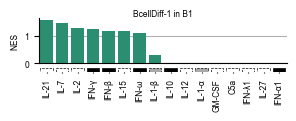

In [447]:
cell_type_data = 'B1 (B_cell)'
cell_type_dict = "B cell"
program = "BcellDiff-1"

cell_type_dataset = cell_type_data.split(" (")[0]
df_nes = _get_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    adata = adata[(adata.obs.labels==cell_type_dataset) & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
    receptor_expression_threshold=0.05,
)

make_plot(df_nes, f"./final_figures/barplot_{program}_{cell_type_dataset}.svg", direction_palette, receptor_palette)

,index,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,0,IL-15,1.938508,#FF007F,1.0,red,True,0.8,0.273185,0.166440,black,
1,1,IL-2,1.689736,#FF007F,1.0,red,True,0.8,0.273185,0.166440,black,
2,2,IL-7,1.668350,#FF007F,1.0,red,True,0.8,0.801504,0.379170,black,
3,3,IFN-ω,1.263128,#FF007F,1.0,red,False,0.5,0.097526,0.062287,black,
4,4,IFN-β,1.251999,#FF007F,1.0,red,False,0.5,0.097526,0.062287,black,
5,5,IFN-γ,1.029008,#FF007F,1.0,red,False,0.5,0.006161,0.004425,white,//


/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.

/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.



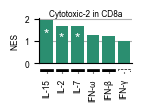

In [466]:
cell_type_data = 'CD8a (CD8_T_cell)'
cell_type_dict = "CD8 T cell"
program = "Cytotoxic-2"

cell_type_dataset = cell_type_data.split(" (")[0]
df_nes = _get_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    adata = adata[(adata.obs.labels==cell_type_dataset) & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
    receptor_expression_threshold=0.05,
)

make_plot(df_nes, f"./final_figures/barplot_{program}_{cell_type_dataset}.svg", direction_palette, receptor_palette)

In [467]:
df_nes

,index,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,0,IL-15,1.938508,#FF007F,1.0,red,True,0.8,0.273185,0.166440,black,
1,1,IL-2,1.689736,#FF007F,1.0,red,True,0.8,0.273185,0.166440,black,
2,2,IL-7,1.668350,#FF007F,1.0,red,True,0.8,0.801504,0.379170,black,
3,3,IFN-ω,1.263128,#FF007F,1.0,red,False,0.5,0.097526,0.062287,black,
4,4,IFN-β,1.251999,#FF007F,1.0,red,False,0.5,0.097526,0.062287,black,
5,5,IFN-γ,1.029008,#FF007F,1.0,red,False,0.5,0.006161,0.004425,white,//


No receptor gene found in cytokine_info for cytokine: IL-32-β


,index,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,0,IL-2,1.695324,#FF007F,1.0,red,True,0.8,1.035242,0.603704,black,
1,1,IL-15,1.681274,#FF007F,1.0,red,True,0.8,1.035242,0.603704,black,
2,2,IL-7,1.615284,#FF007F,1.0,red,True,0.8,1.112038,0.581481,black,
3,3,IFN-ω,1.548289,#FF007F,1.0,red,True,0.8,0.108629,0.092593,black,
4,4,IFN-γ,1.531686,#FF007F,1.0,red,True,0.8,0.021203,0.025926,white,//
5,5,IFN-β,1.303883,#FF007F,1.0,red,False,0.5,0.108629,0.092593,black,
6,6,IL-32-β,0.684481,#FF007F,-1.0,blue,False,0.5,NaN,NaN,lightgray,//
7,7,IL-27,0.000000,NaN,1.0,red,False,0.5,0.088976,0.081481,black,


/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.

/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.



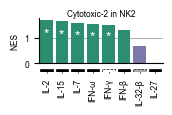

In [449]:
cell_type_data = 'NK2 (NK_CD56hi)'
cell_type_dict = "NK CD56hi"
program = "Cytotoxic-2"

cell_type_dataset = cell_type_data.split(" (")[0]
df_nes = _get_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    adata = adata[(adata.obs.labels==cell_type_dataset) & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
    receptor_expression_threshold=0.05,
)

make_plot(df_nes, f"./final_figures/barplot_{program}_{cell_type_dataset}.svg", direction_palette, receptor_palette)

In [432]:
df_nes

,index,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,0,IL-2,1.695324,#FF007F,1.0,red,True,0.8,1.035242,0.603704,black,
1,1,IL-15,1.681274,#FF007F,1.0,red,True,0.8,1.035242,0.603704,black,
2,2,IL-7,1.615284,#FF007F,1.0,red,True,0.8,1.112038,0.581481,black,
3,3,IFN-ω,1.548289,#FF007F,1.0,red,True,0.8,0.108629,0.092593,black,
4,4,IFN-γ,1.531686,#FF007F,1.0,red,True,0.8,0.021203,0.025926,white,//
5,5,IFN-β,1.303883,#FF007F,1.0,red,False,0.5,0.108629,0.092593,black,
6,6,IL-32-β,0.684481,#FF007F,-1.0,blue,False,0.5,NaN,NaN,lightgray,//
7,7,IL-27,0.000000,NaN,1.0,red,False,0.5,0.088976,0.081481,black,


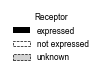

In [463]:
import matplotlib.patches as mpatches

handles = []
labels = []
legend_receptor_palette = {"expressed": "black", "not expressed": "white", "unknown": "lightgray"}
for label, color in legend_receptor_palette.items():
    if color == "black":
        patch = mpatches.Patch(facecolor=color, label=label)
    else:
        patch = mpatches.Patch(facecolor=color, label=label, edgecolor="k", linestyle="--", linewidth = 0.5)
    handles.append(patch)
    labels.append(label)

fig, ax = plt.subplots(figsize=(0.5, 0.3))
legend = ax.legend(handles, labels, loc='center', frameon=False, fontsize=6) 
legend.set_title("Receptor")
legend.get_title().set_fontsize(6)
legend.get_title().set_fontfamily("Arial")
for text in legend.get_texts():
    text.set_fontfamily('Arial')
    text.set_fontsize(6)

ax.axis('off')
plt.savefig(f"./final_figures/legend_receptor_expression.svg", bbox_inches="tight", pad_inches=0, transparent=True)
plt.show()

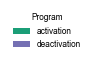

In [465]:
import matplotlib.patches as mpatches

handles = []
labels = []
activation_palette = {"activation": "#1B9E77", "deactivation": "#7570B3",}
for label, color in activation_palette.items():
    patch = mpatches.Patch(facecolor=color, label=label)
    handles.append(patch)
    labels.append(label)

fig, ax = plt.subplots(figsize=(0.5, 0.3))
legend = ax.legend(handles, labels, loc='center', frameon=False, fontsize=6) 
legend.set_title("Program")
legend.get_title().set_fontsize(6)
legend.get_title().set_fontfamily("Arial")
for text in legend.get_texts():
    text.set_fontfamily('Arial')

ax.axis('off')
plt.savefig(f"./final_figures/legend_program_activation.svg", bbox_inches="tight", pad_inches=0, transparent=True)
plt.show()

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.


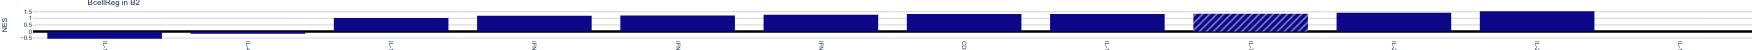

In [8]:
cell_type_data = 'B2 (B_cell)'
cell_type_dict = "B cell"
program = "BcellReg"

_ = make_bar_chart(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    alpha=0.1,
    width = 120,
    height = 50,
    path = f"./results_final_DEGs/figures/bar_plot_{program}_{cell_type_data}_{tissue}.svg",
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    adata = adata[(adata.obs.labels=="B2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

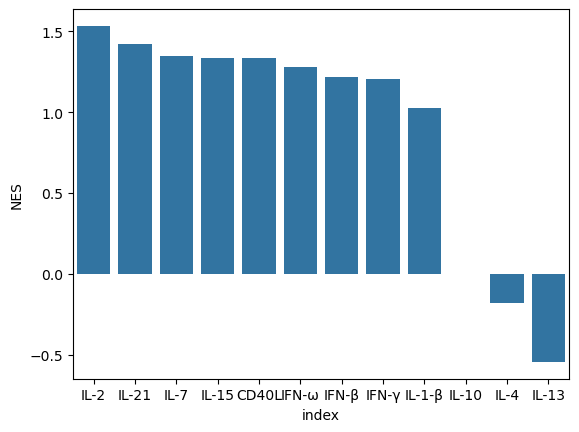

In [10]:
sns.barplot(
    data=_.reset_index(),
    x="index",
    y="NES",
    hue=
)
plt.show()

The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']


,mean_X,frac_X
cytokine,,
IL-2,1.035242,0.603704
IL-15,1.035242,0.603704
IL-12,0.222341,0.162963
IL-10,0.169883,0.133333


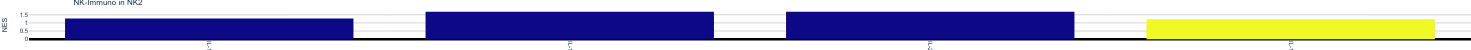

In [239]:
cell_type_data = 'NK2 (NK_CD56hi)'
cell_type_dict = "NK CD56hi"
program = "NK-Immuno"

df_nes = make_bar_chart(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 80,
    height = 50,
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    # path = f"./results_final_DEGs/figures/bar_plot_{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="NK2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)
df_nes = df_nes.reset_index().rename({"index": "cytokine"},axis=1)

In [240]:
df_nes

,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,IL-2,1.695324,#FF007F,-1.0,blue,True,0.8,1.035242,0.603704,black,
1,IL-15,1.681274,#FF007F,-1.0,blue,True,0.8,1.035242,0.603704,black,
2,IL-12,1.274155,#FF007F,-1.0,blue,False,0.5,0.222341,0.162963,black,
3,IL-10,1.221602,#FF007F,1.0,red,False,0.5,0.169883,0.133333,black,


The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']


,mean_X,frac_X
cytokine,,
IL-2,1.035242,0.603704
IL-15,1.035242,0.603704
IL-12,0.222341,0.162963
IL-10,0.169883,0.133333


,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
2,IL-12,1.274155,#FF007F,-1.0,blue,False,0.5,0.222341,0.162963,black,
1,IL-15,1.681274,#FF007F,-1.0,blue,True,0.8,1.035242,0.603704,black,
0,IL-2,1.695324,#FF007F,-1.0,blue,True,0.8,1.035242,0.603704,black,
3,IL-10,1.221602,#FF007F,1.0,red,False,0.5,0.169883,0.133333,black,


/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.



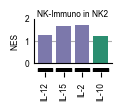

In [241]:
cell_type_data = 'NK2 (NK_CD56hi)'
cell_type_dict = "NK CD56hi"
program = "NK-Immuno"

df_nes = _get_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    adata = adata[(adata.obs.labels=="NK2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)
display(df_nes)
cell_type_dataset = cell_type_data.split(" (")[0]

fig, axs = plt.subplots(2,1,figsize=(0.25 * df_nes.shape[0], 0.7), sharex=True, height_ratios=(0.9, 0.1))
ax = axs[0]
sns.barplot(
    data=df_nes,
    x="cytokine",
    y="NES",
    hue="direction",
    palette=direction_colors,
    legend=False,
    ax=ax,
)
ax.set_title(f"{program} in {cell_type_dataset}", fontsize=6, family="Arial", pad=-2)
ax.set_xlabel("")
ax.set_ylabel("NES", fontsize=6, family="Arial")
ax.tick_params(length=0)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])
yticks = ax.get_yticks()
ytickslabels = ax.get_yticklabels()
ax.set_yticks(yticks, ytickslabels, fontsize=6, family="Arial")
ax.grid(axis="y")
ax.set_axisbelow(True)
ygridlines = ax.get_ygridlines()
top_y = max([tick.get_ydata()[0] for tick in ygridlines])
for line in ygridlines:
    if line.get_ydata()[0] == top_y:
        line.set_visible(False)
axr = axs[1]
axr.spines[['top', 'right', "left", "bottom"]].set_visible(False)
sns.barplot(
    data=df_nes,
    x="cytokine",
    y=0.2,
    hue="color_receptor",
    palette=receptor_palette,
    legend=False,
    ax=axr,
    edgecolor="k",
)
axr.set_xlabel("")
axr.set_ylabel("")
axr.set_yticks([])
axr.set_xticks(np.arange(df_nes.shape[0]), df_nes.cytokine, fontsize=6, family="Arial", rotation=90)
axr.margins(x=0.01)
plt.savefig(f"./final_figures/barplot_{program}_{cell_type_dataset}.svg", bbox_inches="tight", pad_inches=0, transparent=True)
plt.show()

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']
None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-α.


,mean_X,frac_X
cytokine,,
IL-21,0.045205,0.027183
IL-7,0.032595,0.019665
IL-2,0.002404,0.001735
IFN-γ,0.219425,0.131290
IFN-β,0.098530,0.059572
IL-15,0.002404,0.001735
IFN-ω,0.098530,0.059572
IL-10,0.107036,0.064199
IL-12,0.037702,0.023713


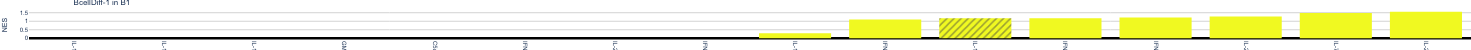

In [281]:
cell_type_data = 'B1 (B_cell)'
cell_type_dict = "B cell"
program = "BcellDiff-1"

df_nes = make_bar_chart(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    alpha=0.1,
    width = 200,
    height = 50,
    # path = f"./results_final_DEGs/figures/bar_plot_{program}_{cell_type_data}_{tissue}.svg",
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    adata = adata[(adata.obs.labels=="B1") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)
df_nes = df_nes.reset_index().rename({"index": "cytokine"},axis=1)

In [293]:
cell_type_data = 'B1 (B_cell)'
cell_type_dict = "B cell"
program = "BcellDiff-1"

df_nes = _get_data(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    adata = adata[(adata.obs.labels=="NK2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)
df_nes = df_nes.sort_values("NES", ascending=False)
cell_type_dataset = cell_type_data.split(" (")[0]



None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']
None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-α.


The following cytokine receptor genes were not found in the dataset and are excluded: ['CRLF2']
None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['BMPR1A']
The following cytokine receptor genes were not found in the dataset and are excluded: ['BMPR1B']
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL17RB']
The following cytokine receptor genes were not found in the dataset and are excluded: ['LIFR']
None of the cytokine receptor genes (['IL20RA' 'IL20RB']) were found in dataset for cytokine IL-19.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL17RC']
None of the cytokine receptor genes (['IL20RA' 'IL20RB']) were found in dataset for cytokine IL-20.
None of the cytokine receptor genes (['IL22RA1' 'IL20RB']) were found in dataset for cytokine IL-20.
None of the cytokine

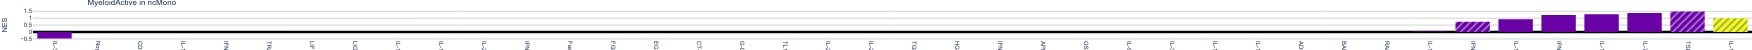

In [223]:
cell_type_data = "ncMono (CD16_Mono)"
cell_type_dict = "CD16 Mono"
program = "MyeloidActive"

nes = make_bar_chart(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 400,
    height = 50,
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    # path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="ncMono") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

,mean_X,frac_X
cytokine,,
IL-15,0.273185,0.166440
IL-2,0.273185,0.166440
IL-7,0.801504,0.379170
IFN-ω,0.097526,0.062287
IFN-β,0.097526,0.062287
IFN-γ,0.006161,0.004425


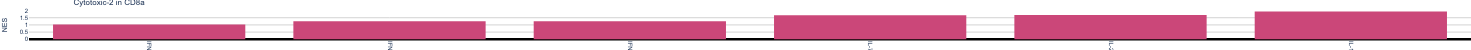

In [186]:
cell_type_data = 'CD8a (CD8_T_cell)'
cell_type_dict = "CD8 T cell"
program = "Cytotoxic-2"

df_nes = make_bar_chart(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    alpha=0.1,
    width = 80,
    height = 50,
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    # path = f"./results_final_DEGs/figures/bar_plot_{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="CD8a") & (adata.obs.MS == "True") & (adata.obs.tissue == tissue)],
    cytokine_info = cytokine_info,
)
df_nes = df_nes.reset_index().rename({"index": "cytokine"},axis=1)

In [187]:
df_nes

,cytokine,NES,color_enrichment,direction,color_direction,significant,opacity_significance,mean_X,frac_X,color_receptor,receptor_pattern
0,IL-15,1.938508,#FF007F,1.0,red,True,0.8,0.273185,0.166440,black,
1,IL-2,1.689736,#FF007F,1.0,red,True,0.8,0.273185,0.166440,black,
2,IL-7,1.668350,#FF007F,1.0,red,True,0.8,0.801504,0.379170,black,
3,IFN-ω,1.263128,#FF007F,1.0,red,False,0.5,0.097526,0.062287,black,
4,IFN-β,1.251999,#FF007F,1.0,red,False,0.5,0.097526,0.062287,black,
5,IFN-γ,1.029008,#FF007F,1.0,red,False,0.5,0.006161,0.004425,black,


/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/seaborn/categorical.py:379: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.



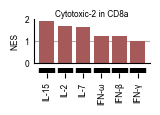

In [173]:
cell_type_dataset = cell_type_data.split(" (")[0]

direction_colors = {1: "#B24C4C", -1: "#4C6EB2",}
receptor_palette = {"black": "k",}

fig, axs = plt.subplots(2,1,figsize=(0.25 * df_nes.shape[0], 0.7), sharex=True, height_ratios=(0.9, 0.1))
ax = axs[0]
sns.barplot(
    data=df_nes,
    x="cytokine",
    y="NES",
    hue="direction",
    palette=direction_colors,
    legend=False,
    ax=ax,
)
ax.set_title(f"{program} in {cell_type_dataset}", fontsize=6, family="Arial", pad=-2)
ax.set_xlabel("")
ax.set_ylabel("NES", fontsize=6, family="Arial")
ax.tick_params(length=0)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])

yticks = [0, 1, 2]
ytickslabels = [str(l) for l in yticks]
ax.set_yticks(yticks, ytickslabels, fontsize=6, family="Arial")
ax.margins(y=0.05)
ax.grid(axis="y")
ax.set_axisbelow(True)
ygridlines = ax.get_ygridlines()
top_y = max([tick.get_ydata()[0] for tick in ygridlines])
for line in ygridlines:
    if line.get_ydata()[0] == top_y:
        line.set_visible(False)
ax.margins(y=0.05)

axr = axs[1]
axr.spines[['top', 'right', "left", "bottom"]].set_visible(False)
sns.barplot(
    data=df_nes,
    x="cytokine",
    y=0.2,
    hue="color_receptor",
    palette=receptor_palette,
    legend=False,
    ax=axr,
    edgecolor="k",
)
axr.set_xlabel("")
axr.set_ylabel("")
axr.set_yticks([])
axr.set_xticks(np.arange(df_nes.shape[0]), df_nes.cytokine, fontsize=6, family="Arial", rotation=90)
axr.margins(x=0.01)
plt.savefig(f"./final_figures/barplot_{program}_{cell_type_dataset}.svg", bbox_inches="tight", pad_inches=0, transparent=True)
plt.show()

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.


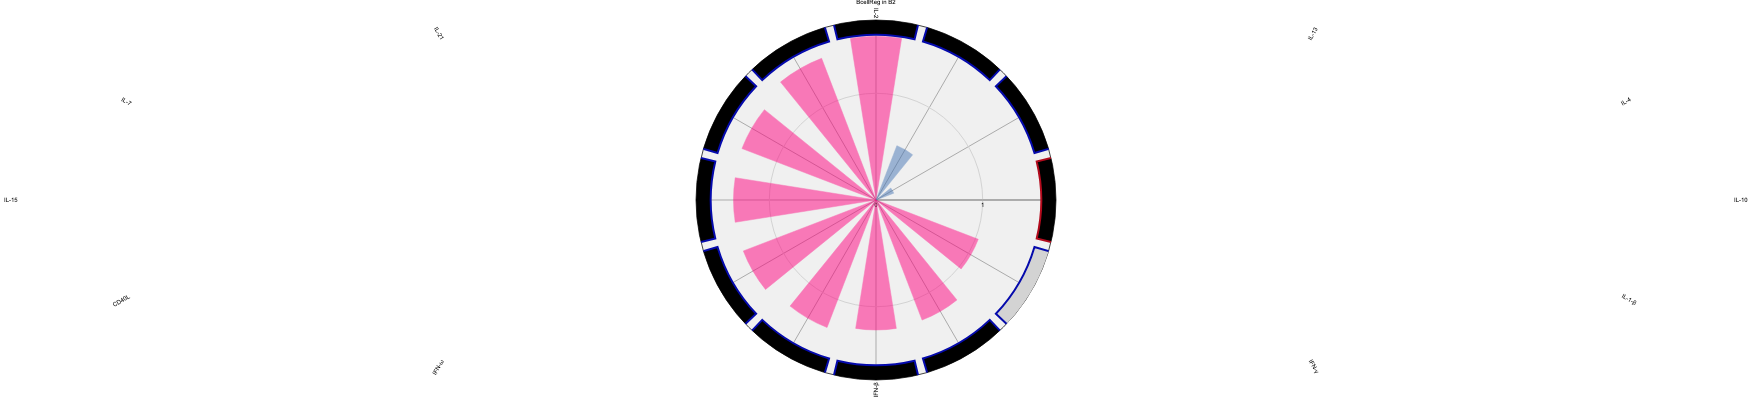

In [15]:
cell_type_data = 'B2 (B_cell)'
cell_type_dict = "B cell"
program = "BcellReg"


plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 400,
    height = 400,
    # path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    adata = adata[(adata.obs.labels=="B2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

In [959]:
cell_type_data = "ncMono (CD16_Mono)"
cell_type_dict = "CD16 Mono"
program = "MyeloidActive"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 120,
    height = 120,
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="ncMono") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

The following cytokine receptor genes were not found in the dataset and are excluded: ['CRLF2']
None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['BMPR1A']
The following cytokine receptor genes were not found in the dataset and are excluded: ['BMPR1B']
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL17RB']
The following cytokine receptor genes were not found in the dataset and are excluded: ['LIFR']
None of the cytokine receptor genes (['IL20RA' 'IL20RB']) were found in dataset for cytokine IL-19.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL17RC']
None of the cytokine receptor genes (['IL20RA' 'IL20RB']) were found in dataset for cytokine IL-20.
None of the cytokine receptor genes (['IL22RA1' 'IL20RB']) were found in dataset for cytokine IL-20.
None of the cytokine

No receptor gene found in cytokine_info for cytokine: IL-32-β


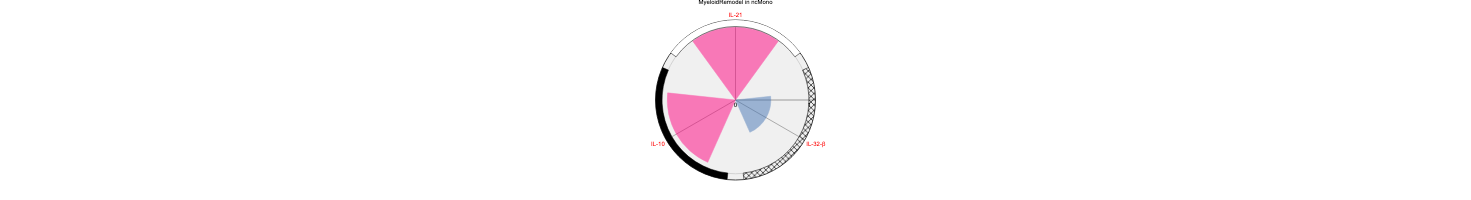

In [818]:
cell_type_data = "ncMono (CD16_Mono)"
cell_type_dict = "CD16 Mono"
program = "MyeloidRemodel"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 200,
    height = 200,
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    # path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="ncMono") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

In [747]:
cell_type_data = "mDC2 (cDC)"
cell_type_dict = "cDC"
program = "MyeloidRemodel"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 80,
    height = 80,
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="mDC2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

No receptor gene found in cytokine_info for cytokine: IL-32-β


ValueError: All objects passed were None

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']
None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-α.


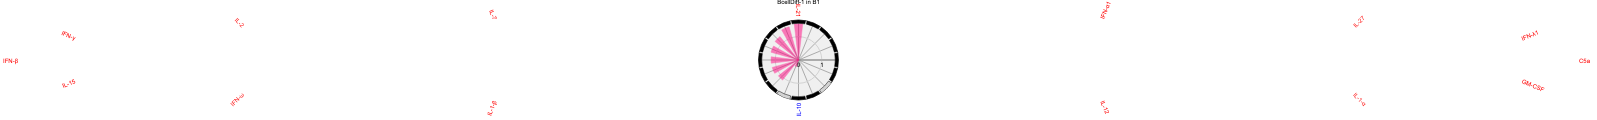

In [947]:
cell_type_data = 'B1 (B_cell)'
cell_type_dict = "B cell"
program = "BcellDiff-1"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 120,
    height = 120,
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="B1") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.


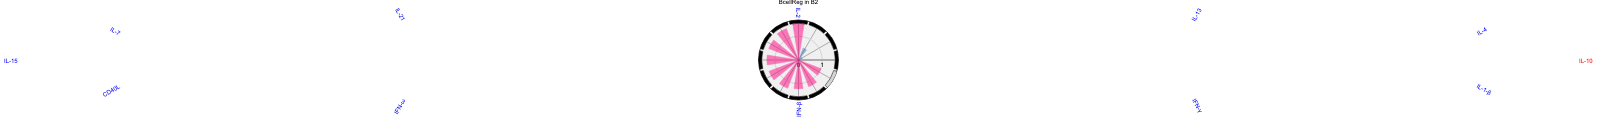

In [948]:
cell_type_data = 'B2 (B_cell)'
cell_type_dict = "B cell"
program = "BcellReg"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 120,
    height = 120,
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    adata = adata[(adata.obs.labels=="B2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']
None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-α.


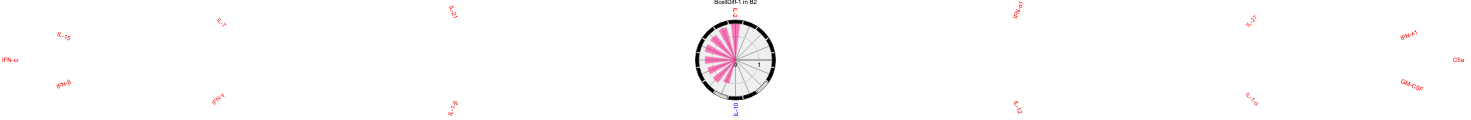

In [949]:
cell_type_data = 'B2 (B_cell)'
cell_type_dict = "B cell"
program = "BcellDiff-1"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 120,
    height = 120,
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    title = f"{program} in {cell_type_data.split(' ')[0]}",
    adata = adata[(adata.obs.labels=="B2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']


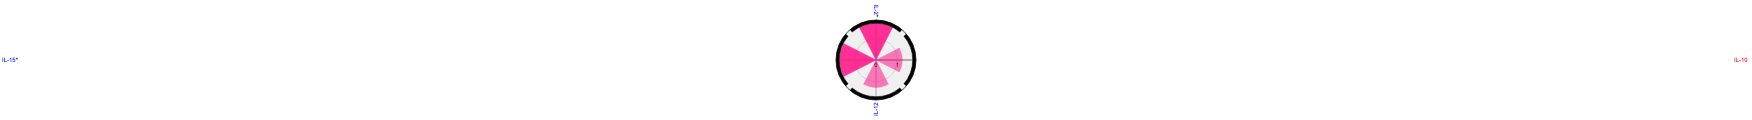

In [950]:
cell_type_data = 'NK2 (NK_CD56hi)'
cell_type_dict = "NK CD56hi"
program = "NK-Immuno"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 120,
    height = 120,
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="NK2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

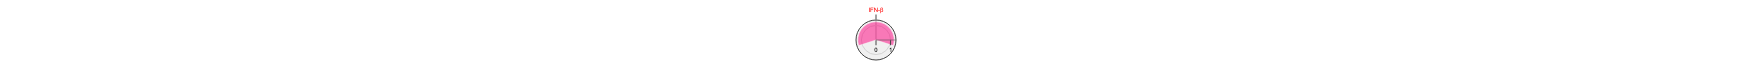

In [753]:
cell_type_data = 'mDC2 (cDC)'
cell_type_dict = "cDC"
program = "MyeloidActive"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 80,
    height = 80,
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="mDC2") & (adata.obs.MS == "True") & (adata.obs.tissue == "blood")],
    cytokine_info = cytokine_info,
)

The following cytokine receptor genes were not found in the dataset and are excluded: ['IL12RB2']


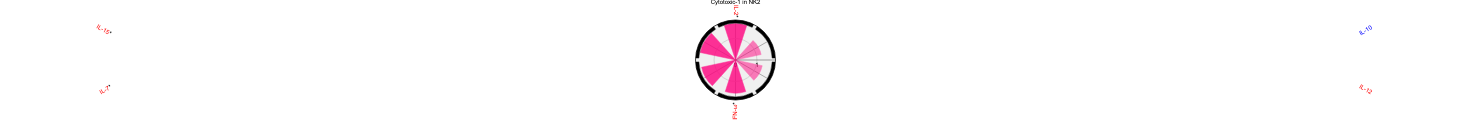

In [951]:
cell_type_data = "NK2 (NK_CD56hi)"
cell_type_dict = "NK CD56hi"
program = "Cytotoxic-1"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 120,
    height = 120,
    title = "Cytotoxic-1 in NK2",
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="NK2") & (adata.obs.MS == "True") & (adata.obs.tissue == tissue)],
    cytokine_info = cytokine_info,
)

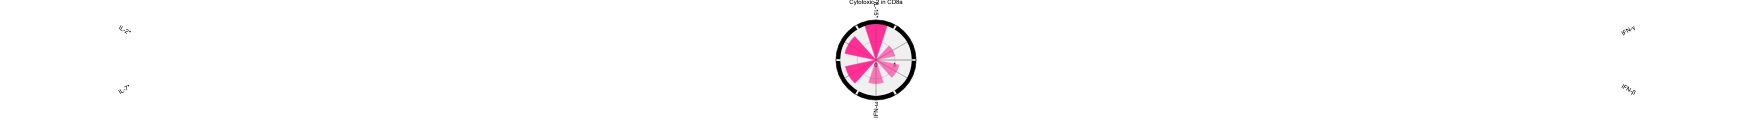

In [46]:
cell_type_data = 'CD8a (CD8_T_cell)'
cell_type_dict = "CD8 T cell"
program = "Cytotoxic-2"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 120,
    height = 120,
    title = "Cytotoxic-2 in CD8a",
    path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="CD8a") & (adata.obs.MS == "True") & (adata.obs.tissue == tissue)],
    cytokine_info = cytokine_info,
)

In [792]:
tissue = "csf"
results = pd.read_csv(f"./results_final_DEGs/results_MS_{tissue}_robustness_new.csv")
results.loc[:, "cytokine"] = results.cytokine.apply(replace_greek)
results = results.loc[results.threshold_expression >= THRESHOLD_EXPRESSION]
results = results.loc[results.percent_duplicate_ranking_stats < THRESHOLD_DUPLICATES]
results_pivot, df_annot, results_robust = get_robust_significant_results(
    results,
    alphas=[0.1, 0.05, 0.01],
    threshold_valid=THRESHOLD_VALID,
    threshold_below_alpha=THRESHOLD_BELOW_ALPHA
)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

None of the cytokine receptor genes (['IL1R1' 'IL1RAP']) were found in dataset for cytokine IL-1-β.
The following cytokine receptor genes were not found in the dataset and are excluded: ['CRLF2']
The following cytokine receptor genes were not found in the dataset and are excluded: ['BMPR1A']
The following cytokine receptor genes were not found in the dataset and are excluded: ['BMPR1B']
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL17RB']
The following cytokine receptor genes were not found in the dataset and are excluded: ['LIFR']
None of the cytokine receptor genes (['IL20RA' 'IL20RB']) were found in dataset for cytokine IL-19.
The following cytokine receptor genes were not found in the dataset and are excluded: ['IL17RC']
None of the cytokine receptor genes (['IL20RA' 'IL20RB']) were found in dataset for cytokine IL-20.
None of the cytokine receptor genes (['IL22RA1' 'IL20RB']) were found in dataset for cytokine IL-20.
None of the cytokine

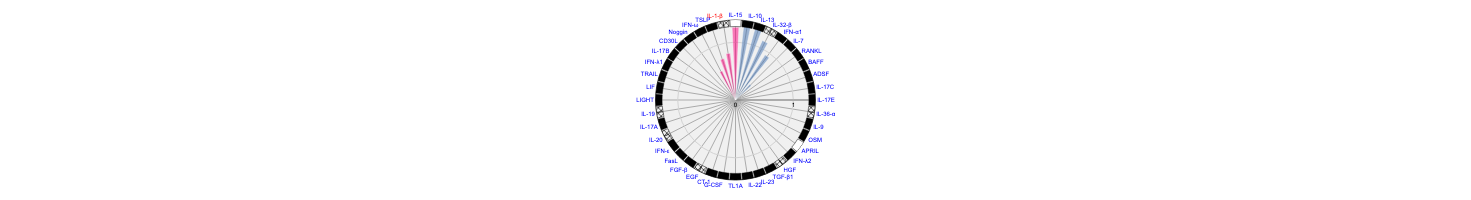

In [796]:
cell_type_data = "ncMono (CD16_Mono)"
cell_type_dict = "CD16 Mono"
program = "MyeloidActive"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 200,
    height = 200,
    # path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_{tissue}.svg",
    adata = adata[(adata.obs.labels=="ncMono") & (adata.obs.MS == "True") & (adata.obs.tissue == tissue)],
    cytokine_info = cytokine_info,
)

In [548]:
cell_type_data = 'CD8a (CD8_T_cell)'
cell_type_dict = "CD8 T cell"
program = "Cytotoxic-2"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 80,
    height = 80,
    title = "Cytotoxic-2 in CD8a",
    # path = f"./results_final_DEGs/figures/{program}_{cell_type_data}_csf.svg",
)

,NES
cytokine,
IL-15,1.821883
IL-2,1.510283
IL-7,1.430405
IFN-ω,1.179670
IFN-β,1.057133
IFN-γ,0.785182


,contrast,celltype_combo,cytokine,qval_threshold
0,True_vs_False,CD8a (CD8_T_cell),IL-15,0.01


In [549]:
cell_type_data = 'B2 (B_cell)'
cell_type_dict = "B cell"
program = "BcellDiff-1"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 200,
    height = 200,
    path = None,#f"./results_final_DEGs/figures/{program}_{cell_type_data}.svg",
    debug_display_nes=True,
    alpha=0.1,
)

,NES
cytokine,
IL-1-β,1.540875
IL-7,1.346618
IL-2,1.240810
IL-21,1.107570
IFN-ω,1.087713
IL-15,1.049421
IFN-γ,1.010639
IFN-β,0.664996


,contrast,celltype_combo,cytokine,qval_threshold


,NES,color_enrichment,direction,color_direction,significant,opacity_significance
IL-1-β,1.540875,#FF007F,1.0,#FF007F,False,0.5
IL-7,1.346618,#FF007F,1.0,#FF007F,False,0.5
IL-2,1.240810,#FF007F,1.0,#FF007F,False,0.5
IL-21,1.107570,#FF007F,1.0,#FF007F,False,0.5
IFN-ω,1.087713,#FF007F,1.0,#FF007F,False,0.5
IL-15,1.049421,#FF007F,1.0,#FF007F,False,0.5
IFN-γ,1.010639,#FF007F,1.0,#FF007F,False,0.5
IFN-β,0.664996,#FF007F,1.0,#FF007F,False,0.5
IL-10,0.000000,NaN,-1.0,#4575B4,False,0.5
IL-12,0.000000,NaN,1.0,#FF007F,False,0.5


In [550]:
cell_type_data = 'B2 (B_cell)'
cell_type_dict = "B cell"
program = "BcellReg"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 200,
    height = 200,
    path = None,#f"./results_final_DEGs/figures/{program}_{cell_type_data}.svg",
    debug_display_nes=True,
    alpha=0.1,
)

,NES
cytokine,
IL-1-β,1.540875
IL-7,1.346618
IL-2,1.240810
IL-13,1.218901
IL-4,1.201636
IL-21,1.107570
IFN-ω,1.087713
IL-15,1.049421
IFN-γ,1.010639


,contrast,celltype_combo,cytokine,qval_threshold


,NES,color_enrichment,direction,color_direction,significant,opacity_significance
IL-1-β,1.540875,#FF007F,-1.0,#4575B4,False,0.5
IL-7,1.346618,#FF007F,-1.0,#4575B4,False,0.5
IL-2,1.240810,#FF007F,-1.0,#4575B4,False,0.5
IL-13,1.218901,#FF007F,-1.0,#4575B4,False,0.5
IL-4,1.201636,#FF007F,-1.0,#4575B4,False,0.5
IL-21,1.107570,#FF007F,-1.0,#4575B4,False,0.5
IFN-ω,1.087713,#FF007F,-1.0,#4575B4,False,0.5
IL-15,1.049421,#FF007F,-1.0,#4575B4,False,0.5
IFN-γ,1.010639,#FF007F,-1.0,#4575B4,False,0.5
CD40L,0.719068,#FF007F,-1.0,#4575B4,False,0.5


In [551]:
cell_type_data = 'NK2 (NK_CD56hi)'
cell_type_dict = "NK CD56hi"
program = "NK-Immuno"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 200,
    height = 200,
    path = None,#f"./results_final_DEGs/figures/{program}_{cell_type_data}.svg",
)

,NES
cytokine,
IL-2,1.680713
IL-15,1.584428
IL-12,1.366170
IL-10,1.014521


,contrast,celltype_combo,cytokine,qval_threshold
1,True_vs_False,NK2 (NK_CD56hi),IL-1-β,0.10
2,True_vs_False,NK2 (NK_CD56hi),IL-15,0.05
3,True_vs_False,NK2 (NK_CD56hi),IL-2,0.05


In [552]:
cell_type_data = 'mDC2 (cDC)'
cell_type_dict = "cDC"
program = "cDC-Suppress"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 80,
    height = 80,
    title = "MyeloidRemodel in mDC2",
    alpha=0.05,
)

,NES
cytokine,
IL-2,1.166149
IL-10,-0.256071


,contrast,celltype_combo,cytokine,qval_threshold


In [553]:
cell_type_data = 'mDC2 (cDC)'
cell_type_dict = "cDC"
program = "ChemokineRemodel"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 80,
    height = 80,
    title = "MyeloidRemodel in mDC2",
    debug_display_nes=True,
)

,NES
cytokine,
IFN-ω,1.450427
IFN-β,1.418716


,contrast,celltype_combo,cytokine,qval_threshold


,NES,color_enrichment,direction,color_direction,significant,opacity_significance
IFN-ω,1.450427,#FF007F,1.0,#FF007F,False,0.5
IFN-β,1.418716,#FF007F,1.0,#FF007F,False,0.5


In [554]:
cell_type_data = 'B2 (B_cell)'
cell_type_dict = "B cell"
program = "BcellDiff-1"

plot_cytokines(
    results,
    results_robust,
    significant_effects_df,
    cell_type_dict = cell_type_dict,
    cell_type_data = cell_type_data,
    program = program,
    cell_type_data_column = "celltype_combo",
    cytokine_column = "cytokine",
    width = 200,
    height = 200,
    path = None,#f"./results_final_DEGs/figures/{program}_{cell_type_data}.svg",
    debug_display_nes=False,
    alpha=0.1,
)

,NES
cytokine,
IL-1-β,1.540875
IL-7,1.346618
IL-2,1.240810
IL-21,1.107570
IFN-ω,1.087713
IL-15,1.049421
IFN-γ,1.010639
IFN-β,0.664996


,contrast,celltype_combo,cytokine,qval_threshold


In [400]:
significant_effects_df.loc[
    (
        (significant_effects_df.cell_type == "B cell")
        &(significant_effects_df.process_id.str.contains("BcellReg"))
        
    )
]

,Unnamed: 0.1,Unnamed: 0,cell_type,cyt,title,diff_normalized,n_diff_donors,direction,is_significant,process_id,abs_diff_normalized
99,99,5378,B cell,IL-15,DR 5,-0.183638,11.0,-1.0,1.0,PD-04 BcellReg,0.183638
186,186,2664,B cell,IFN-β,DR 5,-0.195719,10.0,-1.0,1.0,PD-04 BcellReg,0.195719
278,278,4198,B cell,IL-4,DR 5,-0.179363,9.0,-1.0,1.0,PD-04 BcellReg,0.179363
282,282,6676,B cell,IL-21,DR 5,-0.116266,9.0,-1.0,1.0,PD-04 BcellReg,0.116266
350,350,3962,B cell,IL-2,DR 5,-0.162912,9.0,-1.0,1.0,PD-04 BcellReg,0.162912
360,360,3372,B cell,IFN-ω,DR 5,-0.176181,9.0,-1.0,1.0,PD-04 BcellReg,0.176181
544,544,4552,B cell,IL-7,DR 5,-0.132568,7.0,-1.0,1.0,PD-04 BcellReg,0.132568
673,673,1012,B cell,CD40L,DR 5,-0.120727,6.0,-1.0,1.0,PD-04 BcellReg,0.120727
812,812,3726,B cell,IL-1-β,DR 5,-0.114333,5.0,-1.0,1.0,PD-04 BcellReg,0.114333
828,828,4906,B cell,IL-10,DR 5,0.074495,5.0,1.0,1.0,PD-04 BcellReg,0.074495


In [270]:
cell_type_data = 'mDC2 (cDC)'
cell_type_dict = "cDC"
program = "MyeloidActive"

# get program-associated cytokines
cytokines = get_program_associated_cytokines(significant_effects_df, program, cell_type_dict)
display(cytokines)
unique_cytokines = cytokines.cyt.unique()
directions = cytokines.direction.values

# get relevant enrichment results
_results = results.loc[
    (results.loc[:, cell_type_data_column] == cell_type_data) 
    & (results.loc[:, cytokine_column].isin(unique_cytokines))
]
_results

,cyt,direction
904,IFN-β,1.0


,Unnamed: 0,Name,cytokine,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,...,min_size,max_size,permutation_num,weight,seed,threads,num_genes_signature,num_shared_genes_signature,frac_shared_genes_signature,CSF
1034,5,prerank,IFN-β,0.293448,1.259326,0.025014,0.650359,0.85750,100/411,20.11%,...,8,1000,20000,1.0,2025,6,1073.0,411.0,0.383038,False
1221,6,prerank,IFN-β,0.298712,1.278070,0.021151,0.593445,0.82950,93/387,19.60%,...,8,1000,20000,1.0,2025,6,1073.0,387.0,0.360671,False
1400,4,prerank,IFN-β,0.309516,1.318348,0.011224,0.375909,0.68600,91/363,19.91%,...,8,1000,20000,1.0,2025,6,1073.0,363.0,0.338304,False
1576,4,prerank,IFN-β,0.307021,1.311608,0.015039,0.400670,0.69615,86/342,19.85%,...,8,1000,20000,1.0,2025,6,1073.0,342.0,0.318733,False
1749,5,prerank,IFN-β,0.305432,1.301896,0.021351,0.445803,0.72770,81/323,19.96%,...,8,1000,20000,1.0,2025,6,1073.0,323.0,0.301025,False
1916,4,prerank,IFN-β,0.305285,1.299015,0.024377,0.653166,0.73795,57/303,12.47%,...,8,1000,20000,1.0,2025,6,1073.0,303.0,0.282386,False
2769,5,prerank,IFN-β,0.301780,1.282846,0.025800,0.286420,0.72145,78/335,19.20%,...,8,1000,20000,1.0,2025,6,914.0,335.0,0.366521,False
2921,6,prerank,IFN-β,0.313297,1.327312,0.013357,0.225786,0.60310,70/318,16.77%,...,8,1000,20000,1.0,2025,6,914.0,318.0,0.347921,False
3064,4,prerank,IFN-β,0.320985,1.351310,0.009715,0.186301,0.51120,68/298,17.05%,...,8,1000,20000,1.0,2025,6,914.0,298.0,0.326039,False
3206,5,prerank,IFN-β,0.318264,1.342943,0.013938,0.205772,0.53420,71/280,19.77%,...,8,1000,20000,1.0,2025,6,914.0,280.0,0.306346,False


In [213]:
significant_effects_df.loc[significant_effects_df.cell_type == significant_effects_df.process_id.str.contains(program)]

,Unnamed: 0.1,Unnamed: 0,cell_type,cyt,title,diff_normalized,n_diff_donors,direction,is_significant,process_id,abs_diff_normalized
125,125,98234,NK CD56low,IFN-β,DR 39,0.587047,11.0,1.0,1.0,CE-03 Cytotoxic-2,0.587047
126,126,98942,NK CD56low,IFN-ω,DR 39,0.550122,11.0,1.0,1.0,CE-03 Cytotoxic-2,0.550122
168,168,88322,NK CD56hi,IFN-ω,DR 39,0.276377,11.0,1.0,1.0,CE-03 Cytotoxic-2,0.276377
175,175,87614,NK CD56hi,IFN-β,DR 39,0.340102,11.0,1.0,1.0,CE-03 Cytotoxic-2,0.340102
211,211,23894,CD8 T cell,IFN-β,DR 39,0.197062,10.0,1.0,1.0,CE-03 Cytotoxic-2,0.197062
230,230,111568,NKT,IL-15,DR 39,0.359909,10.0,1.0,1.0,CE-03 Cytotoxic-2,0.359909
233,233,100122,NK CD56low,IL-7,DR 39,0.284571,10.0,1.0,1.0,CE-03 Cytotoxic-2,0.284571
258,258,98352,NK CD56low,IFN-γ,DR 39,0.335188,10.0,1.0,1.0,CE-03 Cytotoxic-2,0.335188
285,285,141422,cDC,IFN-ω,DR 39,0.129241,9.0,1.0,1.0,CE-03 Cytotoxic-2,0.129241
303,303,99532,NK CD56low,IL-2,DR 39,0.297195,9.0,1.0,1.0,CE-03 Cytotoxic-2,0.297195


In [202]:
results_robust.loc[
    (
        (results_robust.celltype_combo == 'CD8a (CD8_T_cell)')
        & (results_robust.qval_threshold <= alpha)
    )
]

,contrast,celltype_combo,cytokine,qval_threshold
0,True_vs_False,CD8a (CD8_T_cell),IL-15,0.01
1,True_vs_False,CD8a (CD8_T_cell),IL-2,0.01
2,True_vs_False,CD8a (CD8_T_cell),IL-32-β,0.05
4,True_vs_False,CD8a (CD8_T_cell),IL-7,0.05


In [158]:
# Assuming you have already created your Python list of opacities
nes.loc[:, 'color'] = "red"
opacity_list = nes['opacity_values'].tolist() 

# --- Corrected Main Barpolar Trace ---
fig = go.Figure(go.Barpolar(
    r=rs,
    theta=thetas,
    width=widths,
    
    marker=dict(
        color=nes.color,
        line_color="black",
        line_width=1,
        
        # --- FIX: Set opacity inside the 'marker' dictionary ---
        opacity=opacity_list 
    ),
    # Remove the top-level opacity=... line entirely
    # opacity=nes['opacity_values'].tolist() 
))



In [557]:
-np.log10(0.1)

1.0

In [99]:
results.loc[(results.celltype_combo == "NK2 (NK_CD56hi)"]

,Unnamed: 0,Name,cytokine,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,...,min_size,max_size,permutation_num,weight,seed,threads,num_genes_signature,num_shared_genes_signature,frac_shared_genes_signature,CSF
168,0,prerank,IL-21,0.652331,1.764926,0.000221,0.003223,0.00305,12/23,21.51%,...,8,1000,20000,1.0,2025,6,44.0,23.0,0.522727,False
169,1,prerank,IFN-gamma,0.528449,1.566643,0.003357,0.033313,0.06090,22/42,27.20%,...,8,1000,20000,1.0,2025,6,63.0,42.0,0.666667,False
170,2,prerank,IL-34,0.681702,1.548193,0.017663,0.027932,0.07645,4/10,11.71%,...,8,1000,20000,1.0,2025,6,14.0,10.0,0.714286,False
171,3,prerank,IFN-omega,0.463288,1.518387,0.000201,0.029231,0.10475,52/129,25.08%,...,8,1000,20000,1.0,2025,6,189.0,129.0,0.682540,False
172,4,prerank,IL-1-beta,0.464885,1.497017,0.000857,0.029397,0.12925,45/100,25.23%,...,8,1000,20000,1.0,2025,6,148.0,100.0,0.675676,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7142,3,prerank,IL-1-beta,0.583528,1.455551,0.043001,0.072647,0.18490,4/14,2.25%,...,8,1000,20000,1.0,2025,6,44.0,14.0,0.318182,False
7143,4,prerank,IFN-omega,0.470628,1.263026,0.157096,0.254029,0.60790,10/20,33.35%,...,8,1000,20000,1.0,2025,6,95.0,20.0,0.210526,False
7144,5,prerank,IL-12,0.537480,1.236367,0.190698,0.239557,0.66970,3/10,0.96%,...,8,1000,20000,1.0,2025,6,65.0,10.0,0.153846,False
7145,6,prerank,IFN-beta,0.416621,1.190539,0.223941,0.260531,0.77055,12/28,34.97%,...,8,1000,20000,1.0,2025,6,118.0,28.0,0.237288,False


In [154]:
nes['opacity_values'].values.tolist()

[0.5, 1.0, 1.0, 1.0, 1.0, 1.0]

In [93]:
results.celltype_combo.unique()

array(['CD4 (CD4_T_cell)', 'CD8a (CD8_T_cell)', 'CD8n (CD8_T_cell)',
       'Tregs (Treg)', 'Mono (CD14_Mono)', 'ncMono (CD16_Mono)',
       'B1 (B_cell)', 'B2 (B_cell)', 'NK1 (NK_CD56low)',
       'NK2 (NK_CD56hi)', 'mDC2 (cDC)'], dtype=object)

In [89]:
significant_effects_df.cell_type.unique()

array(['CD14 Mono', 'cDC', 'B cell', 'NK CD56hi', 'CD4 T cell', 'MAIT',
       'Treg', 'CD8 T cell', 'NK CD56low', 'CD16 Mono', 'NKT', 'HSPC'],
      dtype=object)

In [ ]:
cytokines = get_program_associated_cytokines(significant_effects_df, "MyeloidActive", "CD16 Mono")
unique_cytokines = cytokines.cyt.unique()
directions = cytokines.direction.values

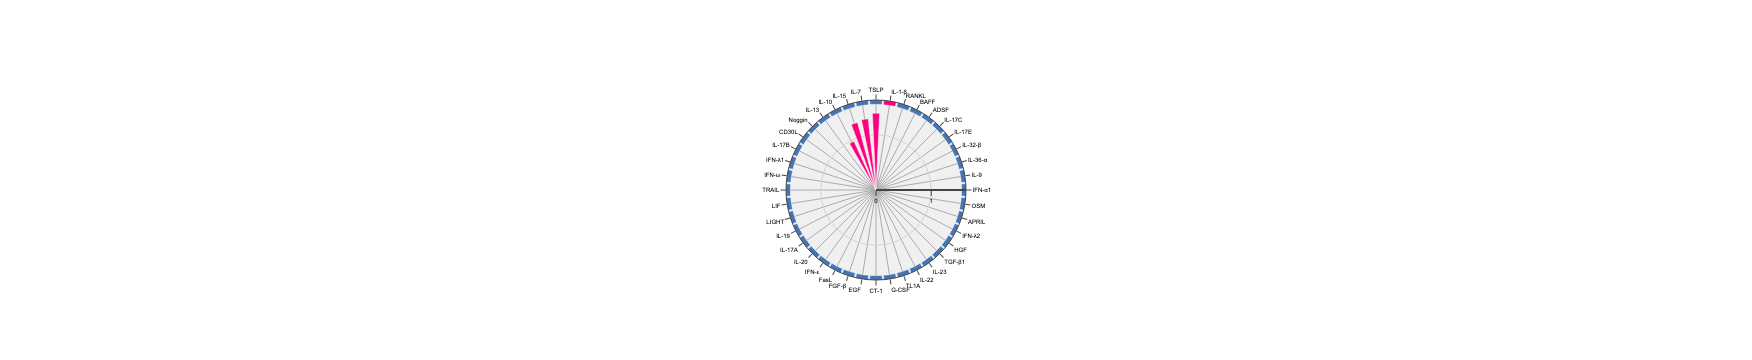

In [75]:
valid_cytokines = np.intersect1d(unique_cytokines, _results.cytokine.unique())
missing_cytokines = cytokines.cyt[~np.isin(unique_cytokines, valid_cytokines)]
nes = _results.set_index("cytokine").loc[valid_cytokines].groupby("cytokine")["NES"].mean().sort_values(ascending=False).to_frame()
missing_nes = pd.DataFrame(np.zeros(len(missing_cytokines)), index=missing_cytokines, columns=["NES"])
nes = pd.concat([nes, missing_nes], axis=0)
nes.loc[nes.NES > 0, "color_enrichment"] = "#FF007F"
nes.loc[nes.NES < 0, "color_enrichment"] = "#4575B4"
nes.loc[:, "direction"] = cytokines.set_index("cyt").loc[nes.index]
nes.loc[nes.direction > 0, "color_direction"] = "#FF007F"
nes.loc[nes.direction < 0, "color_direction"] = "#4575B4"
nes = pd.concat([nes, missing_nes], axis=0).sort_values(["NES", "direction"], ascending=[False, True])

thetas = (np.arange(len(cytokines)) / len(cytokines)) * 360
rs = nes["NES"].values
widths = np.ones_like(thetas) * 0.6 * (360 / len(cytokines))
dtick = thetas[1] - thetas[0]
# max_radius = 1.1 * max(nes["NES"].max(), 2)
max_radius = 1.1 * nes["NES"].max()
ring_start_r = max_radius   
ring_end_r = 1.02 * max_radius

fig = go.Figure(
    go.Barpolar(
        r=rs,
        theta=thetas,
        width=widths,
        marker_color=nes.color_enrichment,
        marker_line_color="white",
        marker_line_width=0.5,
        opacity=1
    )
)

fig.add_trace(
    go.Barpolar(
        base=[ring_end_r-0.01] * len(nes), 
        r=[ring_end_r] * len(nes),
        theta=thetas,
        width=0.9*dtick,
        marker_color=nes.color_direction,
        marker_line_color="white",
        marker_line_width=0.5,
    )
)

fig.update_layout(
    template=None,
    showlegend=False,
    polar = dict(
        bgcolor='#f0f0f0',
        radialaxis = dict(
            linewidth=2,
            showline=True,
            range=[0, max_radius+0.1],
            showticklabels=True,
            showgrid=True,
            tickvals=np.arange(0, max_radius+1, dtype=int),
            gridcolor='lightgray',
            tickfont=dict(
                color='black',
            )
        ),
        angularaxis = dict(
            showticklabels=True,
            ticks="outside",
            dtick=dtick,
            tickvals=thetas,
            ticktext=nes.index,
            tickangle=0,
            rotation=90,
        ),
    ),
    font=dict(
        family="Arial",
        size=6,
        color="black"
    ),
    
)

# fig.write_image("./results_final_DEGs/figures/polar_plot.svg")
fig.show()

In [70]:
nes

,NES,color_enrichment,direction,color_direction
Noggin,0.000000,NaN,-1.0,#4575B4
CD30L,0.000000,NaN,-1.0,#4575B4
IL-17B,0.000000,NaN,-1.0,#4575B4
IFN-λ1,0.000000,NaN,-1.0,#4575B4
IFN-ω,0.000000,NaN,-1.0,#4575B4
...,...,...,...,...
IL-13,0.057794,#FF007F,-1.0,#4575B4
IL-10,0.965652,#FF007F,-1.0,#4575B4
IL-15,1.266112,#FF007F,-1.0,#4575B4
IL-7,1.297637,#FF007F,-1.0,#4575B4


In [ ]:
import plotly.graph_objects as go
import pandas as pd

# 1. Sample Data and Setup (replace with your actual data)
data = {
    'cytokine': ['IL-2', 'IL-4', 'IL-6', 'IL-10', 'IFN-γ', 'TNF-α'],
    'value': [3.5, 1.2, 2.8, 4.1, 1.8, 3.0],
    'color': ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
}
df = pd.DataFrame(data)

# Determine the maximum radial value for the chart's range
max_r_value = df['value'].max()
# Set the desired maximum range for the plot slightly higher than the max data value
plot_range_max = 4.5 

# --- Create the Main Plot (e.g., a Scatterpolar) ---
fig = go.Figure(
    data=[
        go.Scatterpolar(
            r=df['value'],
            theta=df['cytokine'],
            mode='lines+markers',
            name='Main Data',
            line_color='black',
            marker=dict(color=df['color'])
        )
    ]
)

# --- 2. Add the Barpolar Trace for the Outer Color Ring (Patch) ---

# The ring will start just below the maximum range and go up to the max range.
ring_start_r = plot_range_max - 0.2  # e.g., 4.3 (a thin ring)
ring_end_r = plot_range_max           # e.g., 4.5

# Create a trace that spans this small radial range
fig.add_trace(
    go.Barpolar(
        # The 'r' defines the end point of the bar. The 'base' defines the start point.
        r=[ring_end_r] * len(df),
        base=[ring_start_r] * len(df), 
        theta=df['cytokine'],
        marker_color=df['color'],
        width=1,  # Set width to 1 so bars fill the entire angular segment
        hoverinfo='none',
        showlegend=False,
        name='Color Ring'
    )
)

# --- 3. Apply Layout Customizations ---

fig.update_layout(
    polar=dict(
        radialaxis=dict(
            tickvals=[1, 2],
            showgrid=True,
            gridcolor='red',
            linewidth=5,
            tickfont=dict(color='black'),
            # Crucial: The radial axis must extend to the ring's max value (plot_range_max)
            range=[0, plot_range_max] 
        ),
        angularaxis=dict(
            ticktext=df['cytokine'], # Your labels
            showticklabels=True
        )
    ),
    title="Polar Plot with Outer Cytokine Color Ring"
)

# fig.show()